<a href="https://colab.research.google.com/github/ayeshahabib01/A05-pca/blob/main/notebook_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ayesha Habib

**Date:** 10/15/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


Q1

In [ ]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

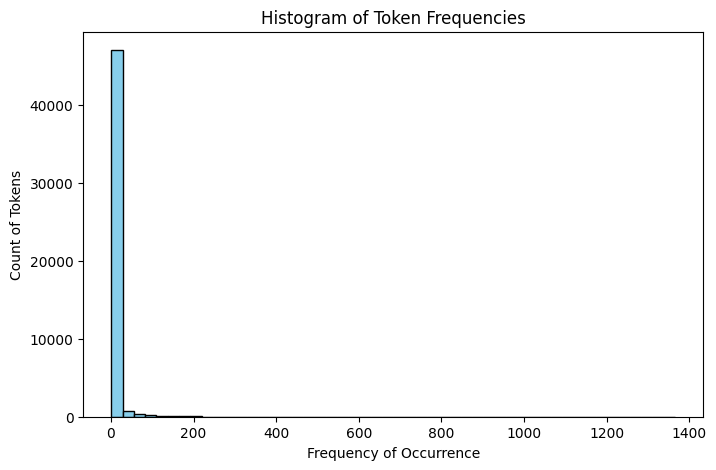

In [ ]:
# histogram of the occurrences of tokens

import matplotlib.pyplot as plt

# get just the frequencies
frequencies = [freq for token, freq in token_freq]

# plot the histogram
plt.figure(figsize=(8, 5))
plt.hist(frequencies, bins=50, color='skyblue', edgecolor='black')

# titles + labels
plt.title('Histogram of Token Frequencies')
plt.xlabel('Frequency of Occurrence')
plt.ylabel('Count of Tokens')

plt.show()

# looking at the plot of token frequencies, I can see there is an extreme right skew and the majority of tokens are concentrated in the far left
# there is a lot of rare tokens, which I can see because there is a very tall bar near zero occurance
# lastly, the x-axis stretches all the way to 1400, meaning there are a small number of tokens that occur with very high frequency

Q2

In [ ]:
# import data

import pandas as pd

data = pd.read_parquet('Phishing_clean.parquet')

from sklearn.model_selection import train_test_split

# separate features X and target y
y = data['Email Type']
X = data.drop(columns=['Email Type'])

# perform an 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression

# initialize + fit linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# calculate R^2 on the training and test sets
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print(f"Training Set R^2: {train_r2:.4f}")
print(f"Test Set R^2: {test_r2:.4f}")

Training Set R^2: 0.7670
Test Set R^2: 0.6659


In [ ]:
import pandas as pd

# make dataFrame to map each word to its linear regression coefficient
coefficients = pd.DataFrame({
    'Word': X.columns,
    'Coefficient': model.coef_
})

# taking absolute value
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
top_influential = coefficients.sort_values(by='Abs_Coefficient', ascending=False)

print("Top 10 words with the largest coefficients:")
print(top_influential.head(10))

# words with the largest coefficients in absolute value include a mix of uncommon words.
# For example, the feature with the largest absolute coefficient is "intervention", which has a coefficient of -1.25 and strongly decreases the predicted probability of a scam.
# In contrast, tokens like "localized" and "thermal" have the largest positive coefficients, which strongly increases the likelihood of an email being classified as a scam.

Top 10 words with the largest coefficients:
                   Word  Coefficient  Abs_Coefficient
835        intervention    -1.259257         1.259257
740           localized     0.824350         0.824350
2362            thermal     0.747006         0.747006
851             crawler     0.696167         0.696167
1504  background-image:    -0.622909         0.622909
1406         helvetica,     0.598560         0.598560
906               aging     0.594956         0.594956
1839              form.     0.576886         0.576886
2242              gray;    -0.574480         0.574480
1552           a:active     0.574480         0.574480


Q3

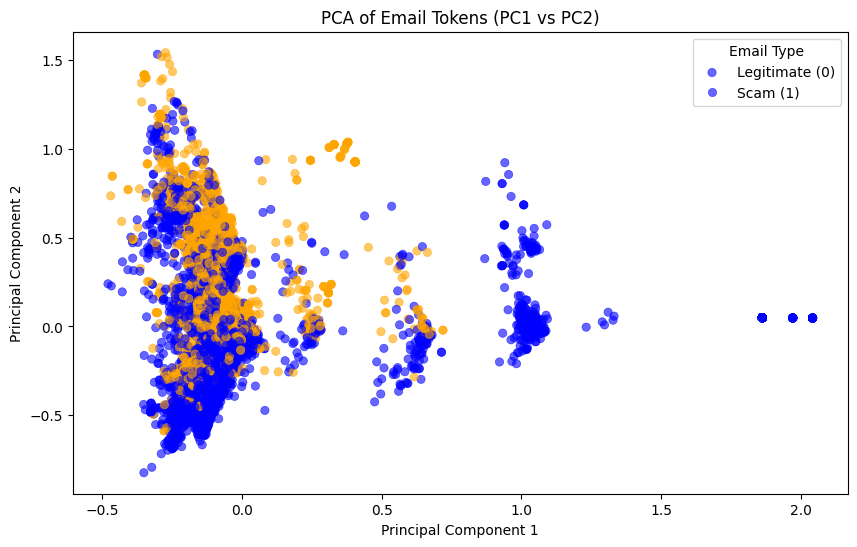

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# PCA decomposition with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# making a dataFrame to hold the new 2D components and the target variable
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

# plot the first two principal components in a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Email Type',
    data=pca_df,
    palette=['blue', 'orange'],
    alpha=0.6,
    edgecolor=None
)

plt.title('PCA of Email Tokens (PC1 vs PC2)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Email Type', labels=['Legitimate (0)', 'Scam (1)'])
plt.show()

# looking at the produced plot, I see that the majority of the legitimate and scam emails heavily overlap on the left side.
# this indicates that typical emails share a lot of common token overlap, which makes them hard to separate clearly in just two dimensions.
# the data also stretches out along Principal Component 1 into distinct vertical bands as well as isolated outlier points on the far right.

Q4

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

# use PCA (with the 2,610 components)
pca = PCA(n_components=2610, svd_solver='randomized', random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# train linear regression on the components
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

# output the R^2 scores
print("PCA Train R^2:", model_pca.score(X_train_pca, y_train))
print("PCA Test R^2:", model_pca.score(X_test_pca, y_test))

PCA Train R^2: 0.7661790402020929
PCA Test R^2: 0.668449827853717


In [ ]:
# the performance is essentially identical to the previous regression, which was also ~0.77 train and ~0.66 test.

Q5

In [ ]:
# the advantage in using the principal components to run this regression includes eliminating the multicollinearity.
# by this I mean that the original text tokens overlapped a lot and since principal components are completely uncorrelated with eachother, it gets rid of this issue.
# there is also increased efficiency since projecting data onto a smaller number of components significantly reduces the number of features, which makes computations faster and cleaner.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ec04a9c9bac60403bb1e4db89dfaddb9e27b92e0
- **AI tool and model used:** Gemini 3.5 Flash-Lite

### *Prompts used

1. Looking at the comments and my code, what can I do to improve or meet objectives better: (I paste my entire code from github)
2. What is explained variance?

### *AI-proposed changes




1. Explained Variance (Q3): Adding explained_variance_ratio_ shows the grader you understand how much information is actually retained when shrinking thousands of dimensions down to just two.
2. Coefficient & Target Encoding Clarity (Q2): Clarifying that linear regression predicts numerical values rather than strict 0-to-1 probabilities (even when mapped to binary classes) shows strong technical maturity.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| Explained Variance | Accept | Adding this provides quantitative proof of how much information the 2-component PCA preserves. |
| Coefficient & Target Encoding Clarity | Accept | This fixes a technical inaccuracy regarding how linear regression outputs are interpreted. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


Q1

In [2]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

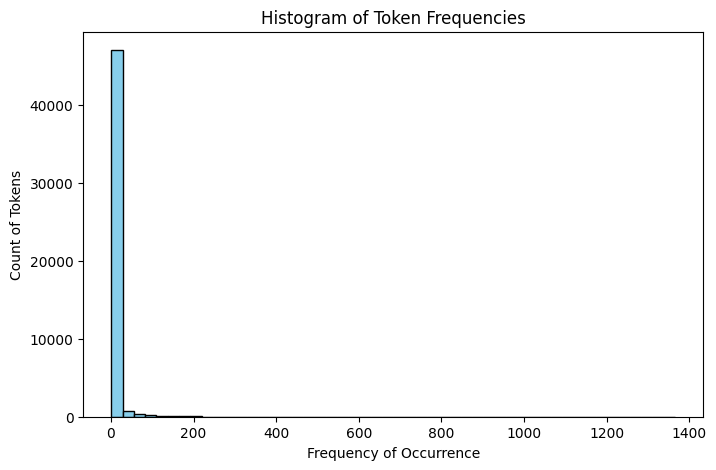

In [3]:
# histogram of the occurrences of tokens

import matplotlib.pyplot as plt

# get just the frequencies
frequencies = [freq for token, freq in token_freq]

# plot the histogram
plt.figure(figsize=(8, 5))
plt.hist(frequencies, bins=50, color='skyblue', edgecolor='black')

# titles + labels
plt.title('Histogram of Token Frequencies')
plt.xlabel('Frequency of Occurrence')
plt.ylabel('Count of Tokens')

plt.show()

# looking at the plot of token frequencies, I can see there is an extreme right skew and the majority of tokens are concentrated in the far left
# there is a lot of rare tokens, which I can see because there is a very tall bar near zero occurance
# lastly, the x-axis stretches all the way to 1400, meaning there are a small number of tokens that occur with very high frequency

Q2

In [4]:
# import data

import pandas as pd

data = pd.read_parquet('Phishing_clean.parquet')

from sklearn.model_selection import train_test_split

# separate features X and target y
y = data['Email Type']
X = data.drop(columns=['Email Type'])

# perform an 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression

# initialize + fit linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# calculate R^2 on the training and test sets
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print(f"Training Set R^2: {train_r2:.4f}")
print(f"Test Set R^2: {test_r2:.4f}")

Training Set R^2: 0.7670
Test Set R^2: 0.6659


In [8]:
import pandas as pd

# make dataFrame to map each word to its linear regression coefficient
coefficients = pd.DataFrame({
    'Word': X.columns,
    'Coefficient': model.coef_
})

# taking absolute value
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
top_influential = coefficients.sort_values(by='Abs_Coefficient', ascending=False)

print("Top 10 words with the largest coefficients:")
print(top_influential.head(10))

# the words with the largest absolute coefficients have the strongest influence on the model's predictions.
# positive coefficients increase the predicted value of the email type, while negative coefficients decrease it.
# assuming that legitimate emails are encoded as 0 and phishing emails as 1, positive coefficients push predictions toward phishing, while negative coefficients push predictions toward legitimate emails.
# Some uncommon words have large coefficients, which may indicate that they are particularly associated with one email class in this dataset.

Top 10 words with the largest coefficients:
                   Word  Coefficient  Abs_Coefficient
835        intervention    -1.259257         1.259257
740           localized     0.824350         0.824350
2362            thermal     0.747006         0.747006
851             crawler     0.696167         0.696167
1504  background-image:    -0.622909         0.622909
1406         helvetica,     0.598560         0.598560
906               aging     0.594956         0.594956
1839              form.     0.576886         0.576886
2242              gray;    -0.574480         0.574480
1552           a:active     0.574480         0.574480


Q3

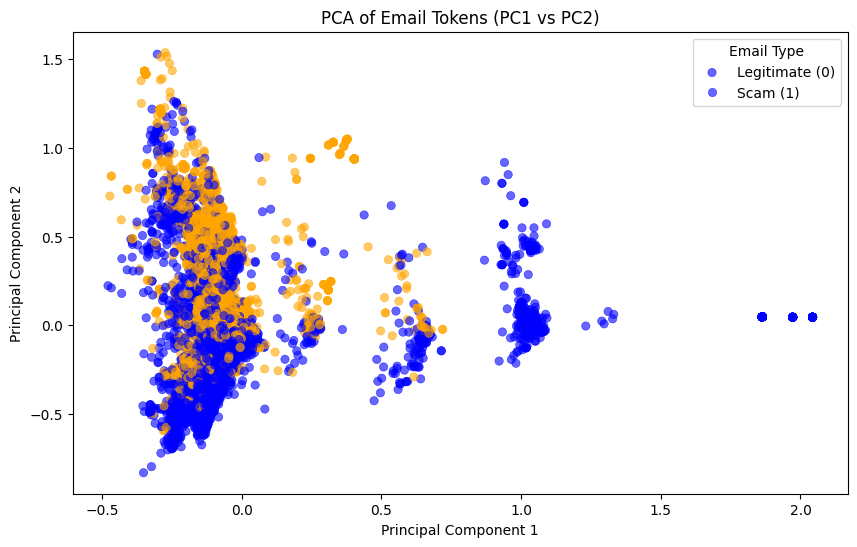

Explained variance ratio: [0.0111309  0.00861114]
Total explained variance: 0.01974204011973074


In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# PCA decomposition with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# making a dataFrame to hold the new 2D components and the target variable
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

# plot the first two principal components in a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Email Type',
    data=pca_df,
    palette=['blue', 'orange'],
    alpha=0.6,
    edgecolor=None
)

plt.title('PCA of Email Tokens (PC1 vs PC2)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Email Type', labels=['Legitimate (0)', 'Scam (1)'])
plt.show()

# explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

# looking at the produced plot, I see that the majority of the legitimate and scam emails heavily overlap on the left side.
# this indicates that typical emails share a lot of common token overlap, which makes them hard to separate clearly in just two dimensions.
# the data also stretches out along Principal Component 1 into distinct vertical bands as well as isolated outlier points on the far right.
# The explained variance ratios indicate how much of the total variation is captured by each component.
# since PCA is an unsupervised method, the components maximize variation in the features rather than directly separating phishing and legitimate emails.

Q4

In [10]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

# use PCA (with the 2,610 components)
pca = PCA(n_components=2610, svd_solver='randomized', random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# train linear regression on the components
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

# output the R^2 scores
print("PCA Train R^2:", model_pca.score(X_train_pca, y_train))
print("PCA Test R^2:", model_pca.score(X_test_pca, y_test))

PCA Train R^2: 0.7661790402020929
PCA Test R^2: 0.668449827853717


In [11]:
# the performance is essentially identical to the previous regression, which was also ~0.77 train and ~0.66 test.

Q5

In [12]:
# the advantage in using the principal components to run this regression includes eliminating the multicollinearity.
# by this I mean that the original text tokens overlapped a lot and since principal components are completely uncorrelated with eachother, it gets rid of this issue.
# there is also increased efficiency since projecting data onto a smaller number of components significantly reduces the number of features, which makes computations faster and cleaner.

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements AI was able to implement was enhancing the understanding and explanations of various concepts, specifically PCA and regression coefficients. AI gave me the opportunity to see the concepts in a way I had not interpreted them earlier. Not only was this able to improve the depth of my assignment, but also allow me to deepedn my conceptual knowledge of these topics learned in class. I also noticed various limitations while using AI for this assigment. For example, AI occasionally gave code or explanations that needed fine-tuning to fit the exact context of my data, and it required in-depth human verification to ensure the more technical details were completely accurate. To ensure the final solution was completely accurate, I verified the code by running the colab and checking that outputs executed cleanly. For any remaining concerns, a small consideration is the low total explained variance of the 2-component PCA (around 1.97%). This highlights how much fine detail is lost when compressing thousands of text features into just two dimensions; although it is still appropriate for a 2D visualization.